# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [ ]:
import os
from scipy import stats
sns.set_style('whitegrid')
os.makedirs('images', exist_ok=True) # folder for charts used in the README

df = pd.read_csv('data/cleaned_aviation_data.csv', low_memory=False)
print(df.shape)
df.head()

(54099, 35)


,event_id,investigation_type,accident_number,event_date,location,country,airport_code,airport_name,injury_severity,aircraft_damage,...,publication_date,year,total_passengers,fatal_or_serious,fatal_serious_share,severe_injury,destroyed,make_model,plane_type,part121
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,ONP,NEWPORT MUNICIPAL,Non-Fatal,Substantial,...,NaN,1983,4.0,0.0,0.0,0,0,CESSNA 182P,CESSNA 182,False
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,3YR,MUNICIPAL,Non-Fatal,Substantial,...,NaN,1983,2.0,0.0,0.0,0,0,CESSNA 182RG,CESSNA 182,False
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,78Y,RANKIN,Non-Fatal,Substantial,...,NaN,1983,1.0,0.0,0.0,0,0,CESSNA 182P,CESSNA 182,False
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,CCB,CABLE,Non-Fatal,Substantial,...,NaN,1983,2.0,0.0,0.0,0,0,PIPER PA-28R-200,PIPER PA28,False
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,NaN,SPRINGBROOK,Non-Fatal,Substantial,...,NaN,1983,2.0,0.0,0.0,0,0,CESSNA 140,CESSNA 140,False


In [3]:
# Overall look at the three measures the client cares about
df[['total_passengers', 'fatal_serious_share', 'destroyed', 'severe_injury']].describe()

,total_passengers,fatal_serious_share,destroyed,severe_injury
count,54099.000000,54099.000000,54099.000000,54099.000000
mean,3.381301,0.274486,0.210226,0.306974
std,16.345367,0.430957,0.407473,0.461243
min,1.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000,0.000000
50%,2.000000,0.000000,0.000000,0.000000
75%,2.000000,0.750000,0.000000,1.000000
max,576.000000,1.000000,1.000000,1.000000


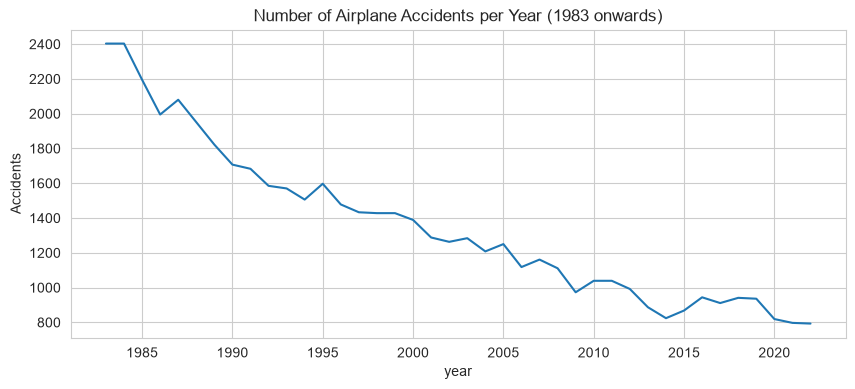

In [4]:
# Number of accidents per year
accidents_per_year = df.groupby('year').size()

plt.figure(figsize=(10, 4))
accidents_per_year.plot()
plt.title('Number of Airplane Accidents per Year (1983 onwards)')
plt.ylabel('Accidents')
plt.savefig('images/accidents_per_year.png', bbox_inches='tight')
plt.show()

**What I see:** accidents have dropped steadily since the 1980s. The `fatal_serious_share` is mostly 0 or 1 for small planes (few people aboard), so I will look at *means* and *distributions* carefully.

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [5]:
THRESHOLD = 20    # passengers

# Statistics for each plane type (family)
type_info = df.groupby('plane_type').agg(
    p90_passengers=('total_passengers', lambda x: x.quantile(0.9)),
    share_part121=('part121', 'mean'),
    accidents=('destroyed', 'size'))

# Large = 90th percentile of people aboard >= 20  OR  at least 25% of its accidents were airline (Part 121) flights
is_large = (type_info['p90_passengers'] >= THRESHOLD) | (type_info['share_part121'] >= 0.25)
large_types = type_info[is_large].index

df['size_group'] = np.where(df['plane_type'].isin(large_types), 'Large', 'Small')

print(df['size_group'].value_counts(), '\n')
print('Most common LARGE plane types:'); print(df[df['size_group'] == 'Large']['plane_type'].value_counts().head(10), '\n')
print('Most common SMALL plane types:'); print(df[df['size_group'] == 'Small']['plane_type'].value_counts().head(5))

size_group
Small    53347
Large      752
Name: count, dtype: int64 

Most common LARGE plane types:
plane_type
BOEING 737                176
DE HAVILLAND DHC6          59
BOEING 747                 49
MCDONNELL DOUGLAS DC9      38
BOEING 757                 38
BOEING 727                 37
BOMBARDIER CL600           33
BOEING 767                 32
MCDONNELL DOUGLAS MD11     29
MCDONNELL DOUGLAS DC10     23
Name: count, dtype: int64 

Most common SMALL plane types:
plane_type
CESSNA 172    6138
PIPER PA28    4264
CESSNA 150    2939
CESSNA 182    2493
CESSNA 152    2243
Name: count, dtype: int64


**How I split small and large planes (threshold of 20 passengers)**

A plane type counts as **Large** if the *90th percentile* of people aboard is 20 or more, or if at least 25% of its accidents were airline flights (Part 121).

*Why not just "any accident with 20+ people"?* I tried it first, but one typo or one unusual flight made a Cessna 172 look like a big airliner. Using the 90th percentile means one odd accident can't change the label, and the Part 121 rule catches cargo jets that often had only 2-3 crew aboard.

The sanity check above shows Boeing/Airbus/McDonnell Douglas jets in Large and Cessna/Piper types in Small, so the rule looks sensible.

In [6]:
# Compare the two groups overall
df.groupby('size_group').agg(accidents=('destroyed', 'size'),
                             mean_fatal_serious_share=('fatal_serious_share', 'mean'),
                             destroyed_rate=('destroyed', 'mean'),
                             severe_injury_rate=('severe_injury', 'mean')).round(3)

,accidents,mean_fatal_serious_share,destroyed_rate,severe_injury_rate
size_group,,,,
Large,752,0.193,0.21,0.354
Small,53347,0.276,0.21,0.306


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

Small makes with enough data: 50
Large makes with enough data: 6 (so fewer than 15 are shown)


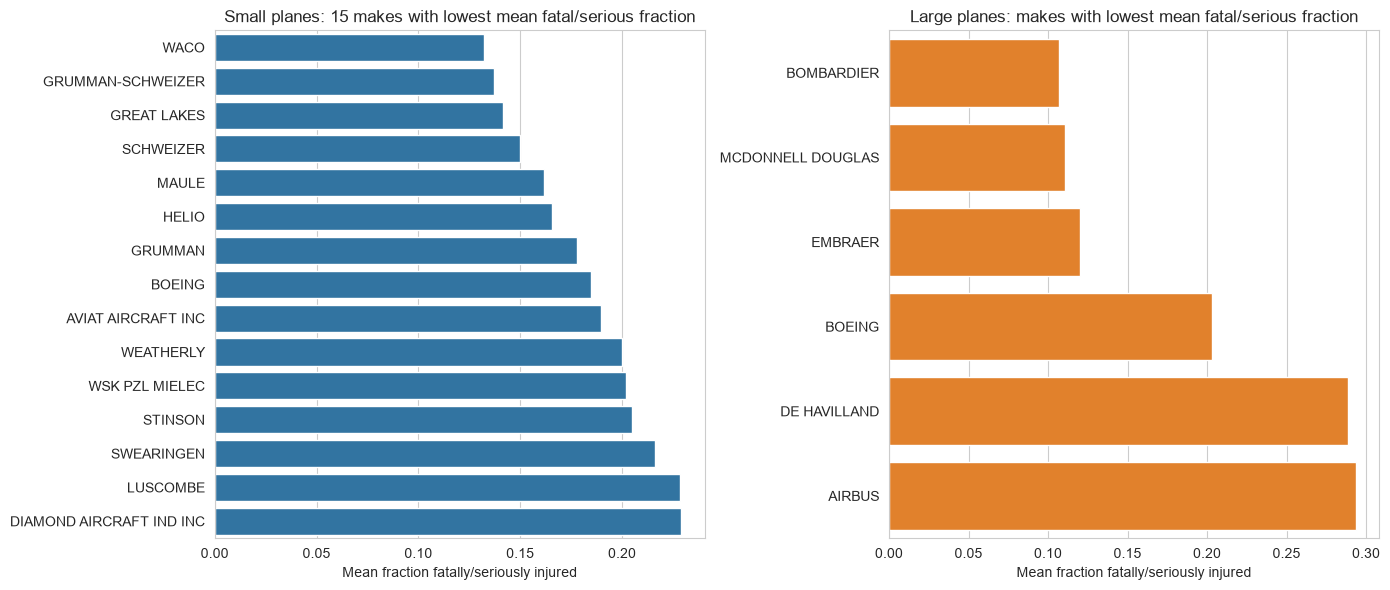

,size_group,make,accidents,mean_fatal_serious_share,destroyed_rate
57,Small,WACO,97,0.132,0.103
36,Small,GRUMMAN-SCHWEIZER,176,0.137,0.153
33,Small,GREAT LAKES,53,0.142,0.113
52,Small,SCHWEIZER,120,0.150,0.225
41,Small,MAULE,495,0.162,0.093
37,Small,HELIO,69,0.166,0.159
34,Small,GRUMMAN,960,0.178,0.229
19,Small,BOEING,308,0.185,0.107
15,Small,AVIAT AIRCRAFT INC,208,0.190,0.062
58,Small,WEATHERLY,75,0.200,0.213


,size_group,make,accidents,mean_fatal_serious_share,destroyed_rate
2,Large,BOMBARDIER,46,0.107,0.087
7,Large,MCDONNELL DOUGLAS,144,0.111,0.167
4,Large,EMBRAER,41,0.120,0.098
1,Large,BOEING,385,0.203,0.226
3,Large,DE HAVILLAND,71,0.289,0.254
0,Large,AIRBUS,60,0.294,0.300


In [7]:
# Statistics for each make inside each size group
make_stats = df.groupby(['size_group', 'make']).agg(
    accidents=('destroyed', 'size'),
    mean_fatal_serious_share=('fatal_serious_share', 'mean'),
    destroyed_rate=('destroyed', 'mean')).reset_index()

# Minimum number of accidents so the averages are reliable
# (smaller for Large because there are far fewer large-plane accidents)
MIN_MAKE = {'Small': 30, 'Large': 10}

top_small = make_stats[(make_stats['size_group'] == 'Small') & (make_stats['accidents'] >= MIN_MAKE['Small'])] \
                .sort_values('mean_fatal_serious_share').head(15)
top_large = make_stats[(make_stats['size_group'] == 'Large') & (make_stats['accidents'] >= MIN_MAKE['Large'])] \
                .sort_values('mean_fatal_serious_share').head(15)

print('Small makes with enough data:', (make_stats[make_stats['size_group']=='Small']['accidents'] >= 30).sum())
print('Large makes with enough data:', len(top_large), '(so fewer than 15 are shown)')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=top_small, y='make', x='mean_fatal_serious_share', color='tab:blue', ax=axes[0])
axes[0].set_title('Small planes: 15 makes with lowest mean fatal/serious fraction')
sns.barplot(data=top_large, y='make', x='mean_fatal_serious_share', color='tab:orange', ax=axes[1])
axes[1].set_title('Large planes: makes with lowest mean fatal/serious fraction')
for ax in axes:
    ax.set_xlabel('Mean fraction fatally/seriously injured'); ax.set_ylabel('')
plt.tight_layout()
plt.savefig('images/makes_injury_fraction.png', bbox_inches='tight')
plt.show()

display(top_small.round(3))
display(top_large.round(3))

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

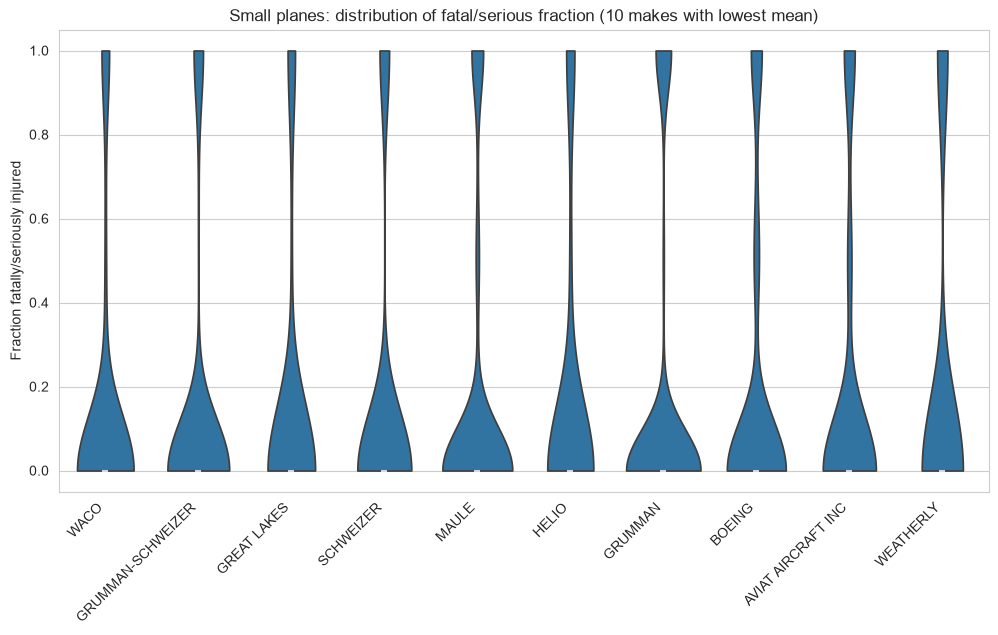

In [8]:
small_order = top_small['make'].head(10).tolist()
small_data = df[(df['size_group'] == 'Small') & (df['make'].isin(small_order))]

plt.figure(figsize=(12, 6))
sns.violinplot(data=small_data, x='make', y='fatal_serious_share', order=small_order, cut=0)
plt.xticks(rotation=45, ha='right')
plt.title('Small planes: distribution of fatal/serious fraction (10 makes with lowest mean)')
plt.ylabel('Fraction fatally/seriously injured'); plt.xlabel('')
plt.savefig('images/small_makes_violin.png', bbox_inches='tight')
plt.show()

**Reading the violin plot:** a fat part near 0 means most accidents of that make had few or no serious injuries; a second bulge near 1 means that in many accidents everyone aboard was seriously hurt or killed.

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

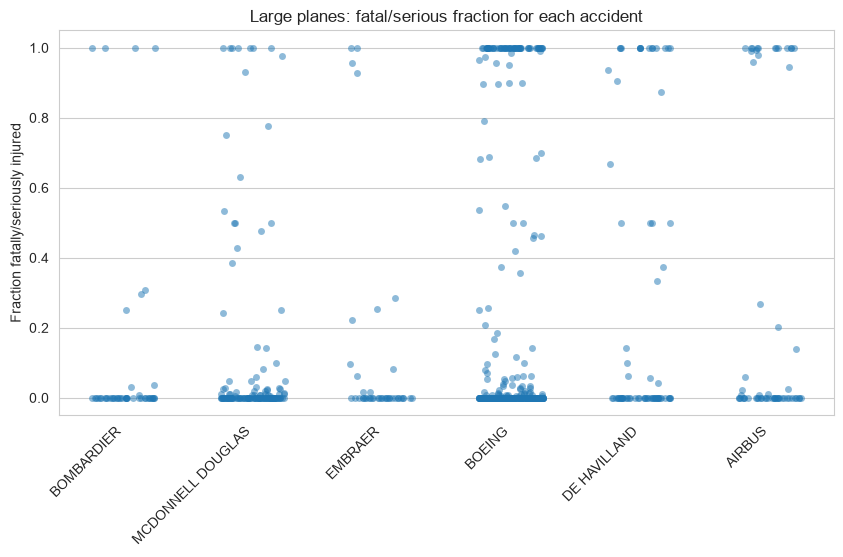

In [9]:
large_order = top_large['make'].head(10).tolist()
large_data = df[(df['size_group'] == 'Large') & (df['make'].isin(large_order))]

plt.figure(figsize=(10, 5))
sns.stripplot(data=large_data, x='make', y='fatal_serious_share', order=large_order, alpha=0.5, jitter=0.25)
plt.xticks(rotation=45, ha='right')
plt.title('Large planes: fatal/serious fraction for each accident')
plt.ylabel('Fraction fatally/seriously injured'); plt.xlabel('')
plt.savefig('images/large_makes_strip.png', bbox_inches='tight')
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

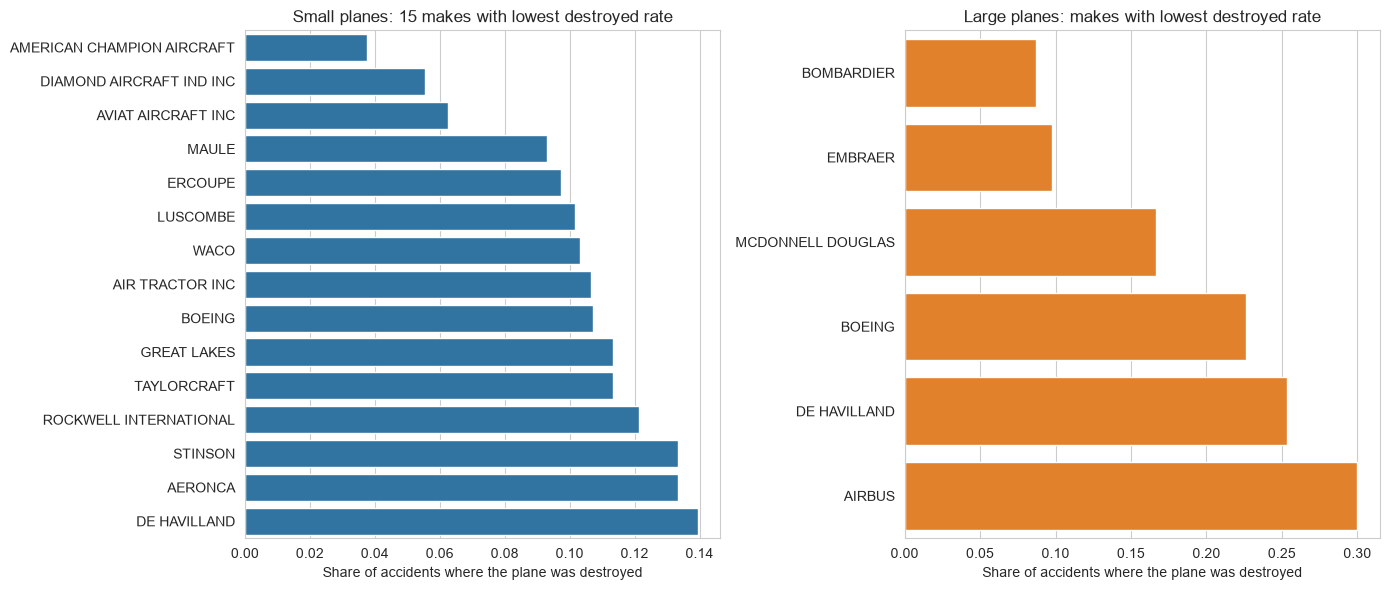

,size_group,make,accidents,mean_fatal_serious_share,destroyed_rate
14,Small,AMERICAN CHAMPION AIRCRAFT,53,0.283,0.038
27,Small,DIAMOND AIRCRAFT IND INC,72,0.229,0.056
15,Small,AVIAT AIRCRAFT INC,208,0.190,0.062
41,Small,MAULE,495,0.162,0.093
29,Small,ERCOUPE,72,0.350,0.097
40,Small,LUSCOMBE,364,0.228,0.102
57,Small,WACO,97,0.132,0.103
12,Small,AIR TRACTOR INC,216,0.340,0.106
19,Small,BOEING,308,0.185,0.107
33,Small,GREAT LAKES,53,0.142,0.113


,size_group,make,accidents,mean_fatal_serious_share,destroyed_rate
2,Large,BOMBARDIER,46,0.107,0.087
4,Large,EMBRAER,41,0.120,0.098
7,Large,MCDONNELL DOUGLAS,144,0.111,0.167
1,Large,BOEING,385,0.203,0.226
3,Large,DE HAVILLAND,71,0.289,0.254
0,Large,AIRBUS,60,0.294,0.300


In [10]:
lowest_destroyed_small = make_stats[(make_stats['size_group'] == 'Small') & (make_stats['accidents'] >= MIN_MAKE['Small'])] \
                            .sort_values('destroyed_rate').head(15)
lowest_destroyed_large = make_stats[(make_stats['size_group'] == 'Large') & (make_stats['accidents'] >= MIN_MAKE['Large'])] \
                            .sort_values('destroyed_rate').head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=lowest_destroyed_small, y='make', x='destroyed_rate', color='tab:blue', ax=axes[0])
axes[0].set_title('Small planes: 15 makes with lowest destroyed rate')
sns.barplot(data=lowest_destroyed_large, y='make', x='destroyed_rate', color='tab:orange', ax=axes[1])
axes[1].set_title('Large planes: makes with lowest destroyed rate')
for ax in axes:
    ax.set_xlabel('Share of accidents where the plane was destroyed'); ax.set_ylabel('')
plt.tight_layout()
plt.savefig('images/makes_destroyed_rate.png', bbox_inches='tight')
plt.show()

display(lowest_destroyed_small.round(3))
display(lowest_destroyed_large.round(3))

**Is the difference between makes real?** Only a handful of makes are compared, so I test it. A chi-square test checks whether the destroyed rate differs across makes, and a Kruskal-Wallis test (good for skewed data like fractions between 0 and 1) checks the fatal/serious fraction. A p-value below 0.05 means the makes do not all behave the same.

In [11]:
for group in ['Small', 'Large']:
    makes_in_group = make_stats[(make_stats['size_group'] == group) & (make_stats['accidents'] >= MIN_MAKE[group])]['make']
    sub = df[(df['size_group'] == group) & (df['make'].isin(makes_in_group))]

    chi2, p_destroyed, dof, exp = stats.chi2_contingency(pd.crosstab(sub['make'], sub['destroyed']))
    samples = [g['fatal_serious_share'] for _, g in sub.groupby('make')]
    h, p_share = stats.kruskal(*samples)
    print(group, '| makes compared:', len(samples), '| destroyed p =', p_destroyed, '| fatal/serious fraction p =', p_share)

Small | makes compared: 50 | destroyed p = 1.616951524329192e-123 | fatal/serious fraction p = 2.973333534447268e-157
Large | makes compared: 6 | destroyed p = 0.02011677533541486 | fatal/serious fraction p = 0.08316344387333045


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

### Discussion: Makes

**Small planes**
- The overall average for small planes is 27.6% of people aboard fatally/seriously injured. The makes with the lowest mean are **Waco (13.2%)**, **Grumman-Schweizer (13.7%)**, **Great Lakes (14.2%)**, **Schweizer (15.0%)** and **Maule (16.2%)**.
- For the destroyed rate, the lowest are **American Champion (3.8%)**, **Diamond (5.6%)**, **Aviat (6.2%)** and **Maule (9.3%)**, compared with about 21% for all small planes.
- **Maule** is the only make near the top of *both* lists, and it has a big sample (495 accidents), so it is my strongest small-plane make recommendation. Aviat, American Champion and Diamond have low destroyed rates but their injury fractions are higher (19-28%), so they are good on one measure only.
- The violin plot shows that for most makes the biggest part of the distribution sits near 0 (nobody badly hurt), with a smaller bulge near 1 (everyone aboard hurt). Means alone hide this "all or nothing" pattern.
- Statistical check: the chi-square test (p about 1e-123) and Kruskal-Wallis test (p about 1e-157) say that small makes really do differ in destroyed rate and injury fraction, so the ranking is not just noise.
- Many of the makes at the top (Waco, Great Lakes, Schweizer, Boeing = Stearman biplanes) are old, slow biplanes or farm planes, so part of their good score may come from how they are flown rather than from the design.

**Large planes**
- Only **6 large makes** have the minimum of 10 accidents, so I can't show 15 as the template asks.
- Lowest mean fatal/serious fraction: **Bombardier (10.7%)**, **McDonnell Douglas (11.1%)**, **Embraer (12.0%)**, then Boeing (20.3%), De Havilland (28.9%) and Airbus (29.4%).
- Lowest destroyed rate: **Bombardier (8.7%)**, **Embraer (9.8%)**, **McDonnell Douglas (16.7%)**, then Boeing (22.6%), De Havilland (25.4%) and Airbus (30.0%).
- The stripplot shows that in most large-plane accidents the fraction is 0 or very low; a smaller number of accidents have a very high fraction, and those pull the means up.
- Statistical check: the destroyed rate differs significantly between large makes (chi-square p = 0.020), but the difference in injury fraction is only borderline (Kruskal-Wallis p = 0.083). So I am fairly confident about the destroyed-rate ranking but less sure about the injury ranking.

**Recommendation for makes:** small planes: **Maule** (best overall), plus Aviat, American Champion and Diamond for low destruction. Large planes: **Bombardier, Embraer and McDonnell Douglas**. 

**Caution:** the dataset only contains planes that had an accident and has no flight hours, so a make with many planes flying (like Boeing or Cessna) will have many accidents simply because it flies a lot. These numbers say how *severe* accidents are, not how *often* they happen.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

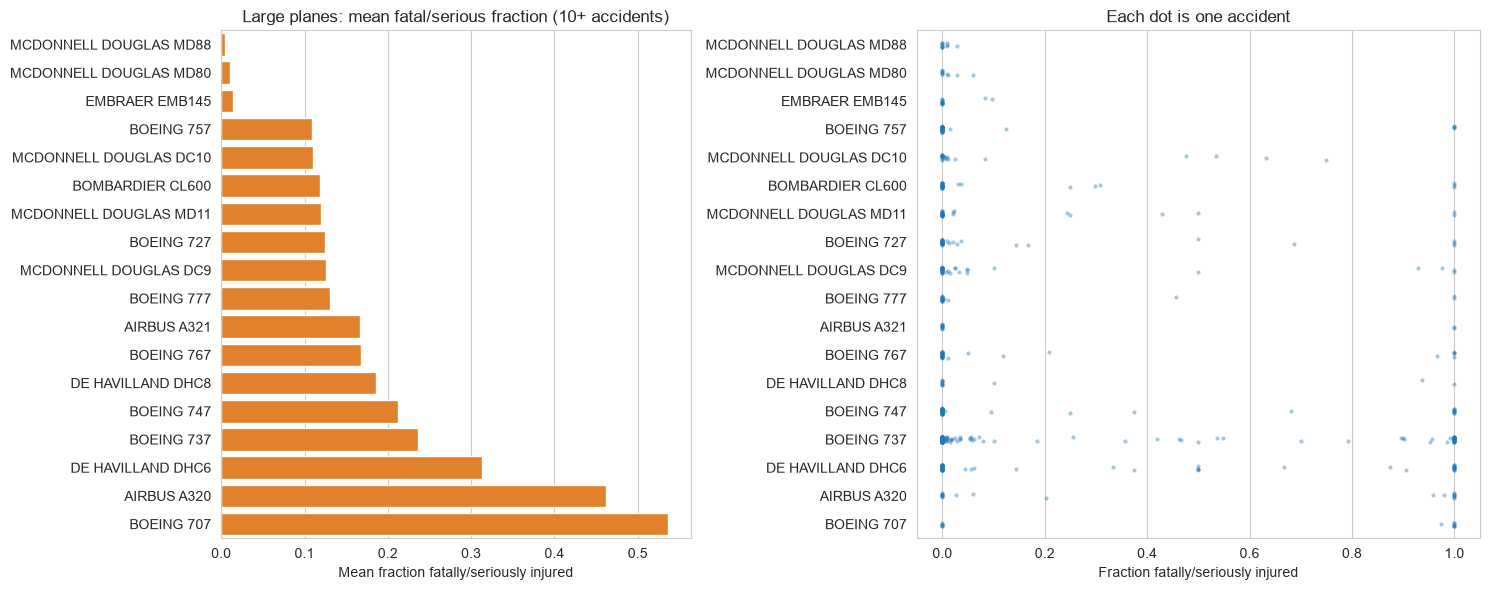

,plane_type,accidents,mean_fatal_serious_share,share_ci_low,share_ci_high,destroyed_rate,destroyed_ci_low,destroyed_ci_high
65,MCDONNELL DOUGLAS MD88,11,0.005,0.000,0.010,0.000,0.000,0.259
61,MCDONNELL DOUGLAS MD80,10,0.011,0.000,0.023,0.000,-0.000,0.278
43,EMBRAER EMB145,13,0.014,0.000,0.032,0.000,0.000,0.228
17,BOEING 757,38,0.109,0.010,0.208,0.105,0.042,0.241
54,MCDONNELL DOUGLAS DC10,23,0.110,0.015,0.206,0.130,0.045,0.321
29,BOMBARDIER CL600,33,0.119,0.018,0.219,0.091,0.031,0.236
60,MCDONNELL DOUGLAS MD11,29,0.120,0.020,0.221,0.207,0.098,0.384
14,BOEING 727,37,0.124,0.028,0.221,0.108,0.043,0.247
56,MCDONNELL DOUGLAS DC9,38,0.125,0.028,0.223,0.211,0.111,0.363
19,BOEING 777,19,0.130,0.000,0.276,0.211,0.085,0.433


In [12]:
MIN_LARGE_TYPE = 10      # at least ten accidents per plane type (as the lab asks)

# helper: 95% Wilson confidence interval for a proportion (e.g. destroyed rate)
def wilson_interval(successes, n, z=1.96):
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    margin = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - margin, centre + margin

type_stats = df.groupby(['size_group', 'plane_type']).agg(
    accidents=('destroyed', 'size'),
    destroyed_n=('destroyed', 'sum'),
    mean_fatal_serious_share=('fatal_serious_share', 'mean'),
    sd_share=('fatal_serious_share', 'std'),
    destroyed_rate=('destroyed', 'mean')).reset_index()

# 95% confidence interval for the mean fraction (mean +/- 1.96 * standard error)
sem = type_stats['sd_share'] / np.sqrt(type_stats['accidents'])
type_stats['share_ci_low'] = (type_stats['mean_fatal_serious_share'] - 1.96 * sem).clip(lower=0)
type_stats['share_ci_high'] = type_stats['mean_fatal_serious_share'] + 1.96 * sem
type_stats['destroyed_ci_low'], type_stats['destroyed_ci_high'] = wilson_interval(type_stats['destroyed_n'], type_stats['accidents'])

large_types_tbl = type_stats[(type_stats['size_group'] == 'Large') & (type_stats['accidents'] >= MIN_LARGE_TYPE)] \
                      .sort_values('mean_fatal_serious_share')

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1, 1.2]})
sns.barplot(data=large_types_tbl, y='plane_type', x='mean_fatal_serious_share', color='tab:orange', ax=axes[0])
axes[0].set_title('Large planes: mean fatal/serious fraction (10+ accidents)')
axes[0].set_xlabel('Mean fraction fatally/seriously injured'); axes[0].set_ylabel('')

large_order_types = large_types_tbl['plane_type'].tolist()
sns.stripplot(data=df[df['plane_type'].isin(large_order_types)], y='plane_type', x='fatal_serious_share',
              order=large_order_types, alpha=0.4, size=3, ax=axes[1])
axes[1].set_title('Each dot is one accident'); axes[1].set_xlabel('Fraction fatally/seriously injured'); axes[1].set_ylabel('')
plt.tight_layout()
plt.savefig('images/large_plane_types.png', bbox_inches='tight')
plt.show()

large_types_tbl[['plane_type', 'accidents', 'mean_fatal_serious_share', 'share_ci_low', 'share_ci_high',
                 'destroyed_rate', 'destroyed_ci_low', 'destroyed_ci_high']].round(3)

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

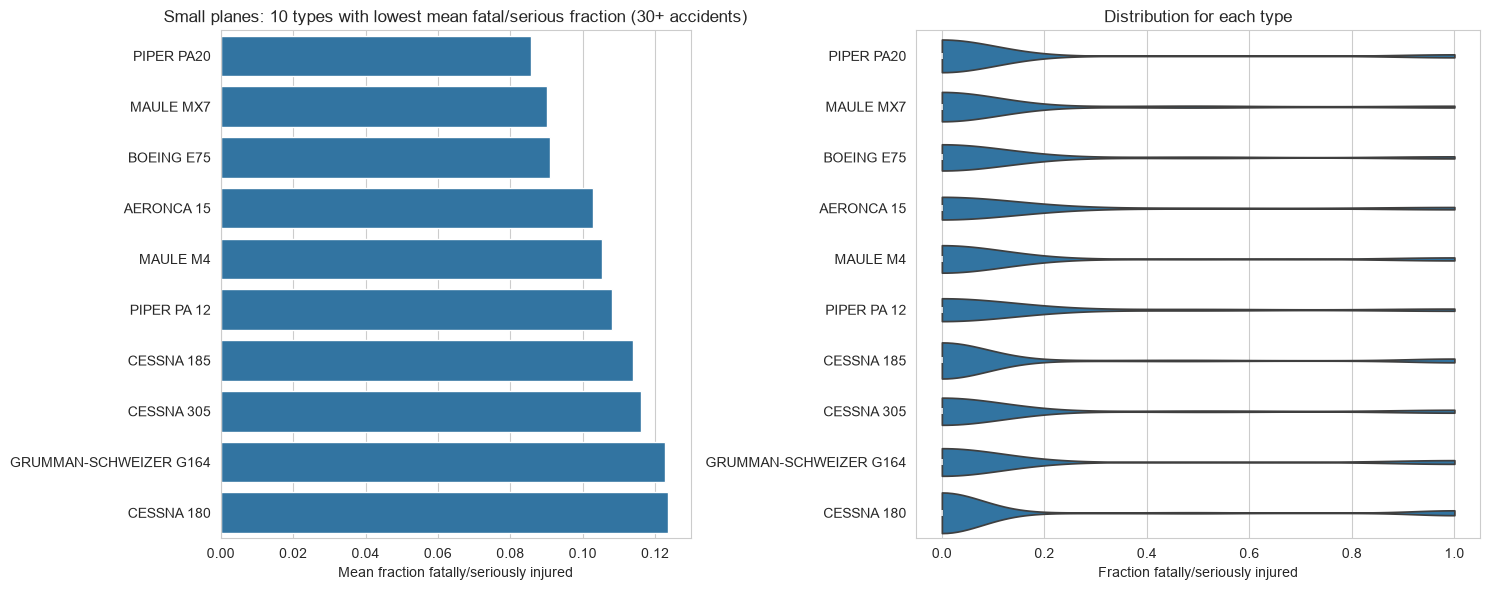

,plane_type,accidents,mean_fatal_serious_share,share_ci_low,share_ci_high,destroyed_rate,destroyed_ci_low,destroyed_ci_high
794,PIPER PA20,134,0.086,0.039,0.133,0.060,0.031,0.113
626,MAULE MX7,62,0.090,0.027,0.153,0.016,0.003,0.086
315,BOEING E75,44,0.091,0.011,0.171,0.114,0.050,0.240
90,AERONCA 15,34,0.103,0.003,0.202,0.029,0.005,0.149
612,MAULE M4,95,0.105,0.045,0.166,0.116,0.066,0.196
706,PIPER PA 12,37,0.108,0.014,0.202,0.054,0.015,0.177
338,CESSNA 185,423,0.114,0.085,0.142,0.102,0.076,0.134
347,CESSNA 305,109,0.116,0.059,0.173,0.083,0.044,0.150
568,GRUMMAN-SCHWEIZER G164,156,0.123,0.072,0.174,0.167,0.116,0.233
336,CESSNA 180,1004,0.124,0.104,0.143,0.085,0.069,0.104


In [13]:
MIN_SMALL_TYPE = 30      # lab minimum is 10, but small planes have plenty of data so I use 30 to be safer

small_types_tbl = type_stats[(type_stats['size_group'] == 'Small') & (type_stats['accidents'] >= MIN_SMALL_TYPE)] \
                      .sort_values('mean_fatal_serious_share').head(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1, 1.2]})
sns.barplot(data=small_types_tbl, y='plane_type', x='mean_fatal_serious_share', color='tab:blue', ax=axes[0])
axes[0].set_title('Small planes: 10 types with lowest mean fatal/serious fraction (30+ accidents)')
axes[0].set_xlabel('Mean fraction fatally/seriously injured'); axes[0].set_ylabel('')

small_order_types = small_types_tbl['plane_type'].tolist()
sns.violinplot(data=df[df['plane_type'].isin(small_order_types)], y='plane_type', x='fatal_serious_share',
               order=small_order_types, cut=0, ax=axes[1])
axes[1].set_title('Distribution for each type'); axes[1].set_xlabel('Fraction fatally/seriously injured'); axes[1].set_ylabel('')
plt.tight_layout()
plt.savefig('images/small_plane_types.png', bbox_inches='tight')
plt.show()

small_types_tbl[['plane_type', 'accidents', 'mean_fatal_serious_share', 'share_ci_low', 'share_ci_high',
                 'destroyed_rate', 'destroyed_ci_low', 'destroyed_ci_high']].round(3)

**Are these differences real or just luck? (statistical check)**

For each of the best plane types I use *Fisher's exact test* to compare how often it was **destroyed** vs all *other* planes in its size group. A p-value below 0.05 means the difference is unlikely to be chance. Because I test many types, I treat p-values near 0.05 as weak evidence.

In [14]:
test_rows = []
for group, tbl in [('Small', small_types_tbl.head(5)), ('Large', large_types_tbl.head(5))]:
    group_df = df[df['size_group'] == group]
    for ptype in tbl['plane_type']:
        is_type = group_df['plane_type'] == ptype
        table = pd.crosstab(is_type, group_df['destroyed'])
        odds, p = stats.fisher_exact(table)
        test_rows.append({'size_group': group, 'plane_type': ptype, 'accidents': is_type.sum(),
                          'destroyed_rate_type': group_df[is_type]['destroyed'].mean(),
                          'destroyed_rate_others': group_df[~is_type]['destroyed'].mean(),
                          'p_value': p})

pd.DataFrame(test_rows).round(4)

,size_group,plane_type,accidents,destroyed_rate_type,destroyed_rate_others,p_value
0,Small,PIPER PA20,134,0.0597,0.2106,0.0000
1,Small,MAULE MX7,62,0.0161,0.2105,0.0000
2,Small,BOEING E75,44,0.1136,0.2103,0.1387
3,Small,AERONCA 15,34,0.0294,0.2103,0.0054
4,Small,MAULE M4,95,0.1158,0.2104,0.0228
5,Large,MCDONNELL DOUGLAS MD88,11,0.0000,0.2132,0.1327
6,Large,MCDONNELL DOUGLAS MD80,10,0.0000,0.2129,0.1319
7,Large,EMBRAER EMB145,13,0.0000,0.2138,0.0816
8,Large,BOEING 757,38,0.1053,0.2157,0.1499
9,Large,MCDONNELL DOUGLAS DC10,23,0.1304,0.2126,0.4425


### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

### Discussion: Specific plane types

I used the plane *family* (e.g. all 737 versions together) so there are more accidents per group.

**Large planes (10+ accidents)**
- The three types with the lowest mean fatal/serious fraction are **McDonnell Douglas MD-88 (0.5%)**, **MD-80 (1.1%)** and **Embraer EMB-145 (1.4%)**, with a destroyed rate of 0% for all three. **But they only have 10-13 accidents each.** The confidence interval for their destroyed rate reaches 23-28%, and Fisher's exact tests are not significant (p = 0.13, 0.13 and 0.08). So I can't claim they are truly safer, it could be luck.
- Types with more data and low risk: **Boeing 757** (38 accidents, 10.9% fatal/serious fraction, 10.5% destroyed), **Bombardier CL-600** (33 accidents, 11.9% / 9.1%) and **Boeing 727** (37 accidents, 12.4% / 10.8%). The 757 compared with other large planes is still not significant (Fisher p = 0.15), so these are *tentative* recommendations.
- Worst outcomes: **Boeing 707** (53.7%), **Airbus A320** (46.1%, only 20 accidents) and **De Havilland DHC-6** (31.3%). The **Boeing 737** has the most data (176 accidents) and a narrow confidence interval (17.7%-29.6%), so its higher-than-average fraction (23.7%) is fairly reliable, but the group mixes many versions and many flights, so I would not call it unsafe from this data alone.

**Small planes (30+ accidents)**
- Lowest mean fatal/serious fraction: **Piper PA-20 (8.6%)**, **Maule MX-7 (9.0%)**, **Boeing E75 Stearman (9.1%)**, **Aeronca 15 (10.3%)**, **Maule M4 (10.5%)**.
- Fisher's exact test on destroyed rate vs other small planes: **PA-20 (6.0% vs 21.1%, p < 0.001)**, **Maule MX-7 (1.6%, p < 0.001)**, **Aeronca 15 (2.9%, p = 0.005)** and **Maule M4 (11.6%, p = 0.023)** are significantly better. The Stearman is not (p = 0.14).
- The best-evidenced picks are the ones with big samples: **Cessna 180** (1,004 accidents, 12.4% fraction, 8.5% destroyed) and **Cessna 185** (423 accidents, 11.4%, 10.2%) have very tight confidence intervals, so their good results are very reliable even though the numbers are not the very lowest.
- Many of these are older tailwheel/bush planes, so they might be safer because of how and where they are flown.

**Recommendations for plane types:** 
- Small: **Piper PA-20, Maule MX-7, Maule M4, Cessna 180/185**. 
- Large: **Boeing 757, Bombardier CL-600, Boeing 727** (tentative); MD-80/88 and Embraer 145 look good but have too few accidents to be sure.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

,size_group,weather_condition,accidents,destroyed_rate,severe_injury_rate,mean_fatal_serious_share
0,Large,IMC,111,0.351,0.550,0.324
1,Large,VMC,411,0.102,0.263,0.107
2,Small,IMC,4138,0.604,0.730,0.697
3,Small,VMC,47415,0.167,0.254,0.224


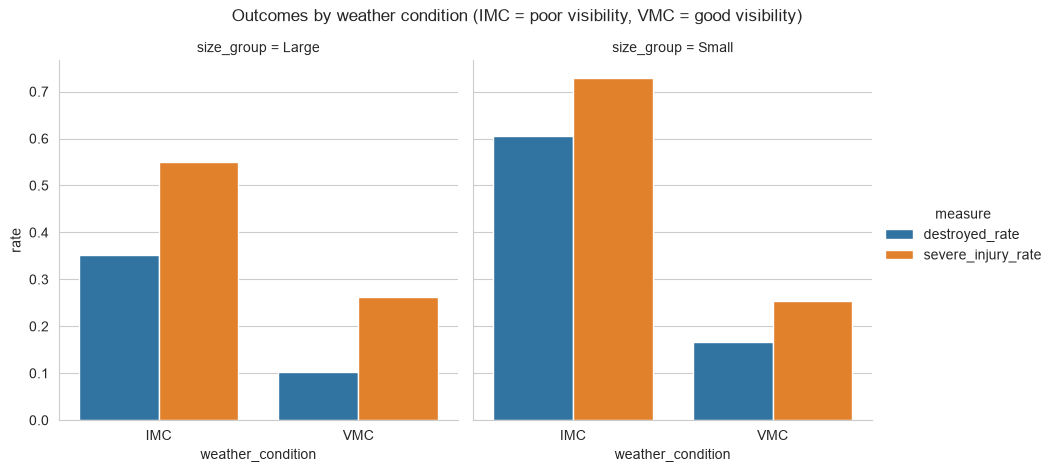

Small weather vs destroyed: chi-square p-value = 0.0
Large weather vs destroyed: chi-square p-value = 3.26529734442499e-10


In [15]:
# Prepare small helper: summary of outcomes by a column, for each size group
def outcome_table(data, col):
    return data.groupby(['size_group', col]).agg(
        accidents=('destroyed', 'size'),
        destroyed_rate=('destroyed', 'mean'),
        severe_injury_rate=('severe_injury', 'mean'),
        mean_fatal_serious_share=('fatal_serious_share', 'mean')).reset_index()

weather_df = df.dropna(subset=['weather_condition'])
weather_tbl = outcome_table(weather_df, 'weather_condition')
display(weather_tbl.round(3))

plot_data = weather_tbl.melt(id_vars=['size_group', 'weather_condition'],
                             value_vars=['destroyed_rate', 'severe_injury_rate'], var_name='measure', value_name='rate')
g = sns.catplot(data=plot_data, kind='bar', x='weather_condition', y='rate', hue='measure', col='size_group', height=4.5)
g.fig.suptitle('Outcomes by weather condition (IMC = poor visibility, VMC = good visibility)', y=1.04)
g.savefig('images/weather.png', bbox_inches='tight')
plt.show()

# Chi-square test: are weather and 'destroyed' related?
for group in ['Small', 'Large']:
    sub = weather_df[weather_df['size_group'] == group]
    chi2, p, dof, exp = stats.chi2_contingency(pd.crosstab(sub['weather_condition'], sub['destroyed']))
    print(group, 'weather vs destroyed: chi-square p-value =', p)

**Factor 1 - Weather condition: discussion**

Poor-visibility weather (**IMC**) is much worse than good weather (**VMC**) for both small and large planes.
- **Small planes:** in IMC, 60.4% of accidents destroyed the plane vs 16.7% in VMC, and 73.0% had a fatal/serious injury vs 25.4%. The mean fraction of people fatally/seriously injured is 69.7% vs 22.4%.
- **Large planes:** 35.1% destroyed in IMC vs 10.2% in VMC, and 55.0% vs 26.3% with a fatal/serious injury.
- The chi-square test gives a p-value of about 0 for small planes and 4e-10 for large planes, so this is not due to chance.
- Only about 8% of small-plane accidents happen in IMC, so it is rare but extremely costly. **Note:** this is a relationship, not proof of cause. Accidents in IMC often involve other things too, like loss of control or pilots without instrument training.

### Factor 2: Number of engines

,size_group,engines,accidents,destroyed_rate,severe_injury_rate,mean_fatal_serious_share
0,Large,1,1,0.000,1.000,0.500
1,Large,2,415,0.133,0.284,0.132
2,Large,3+,113,0.133,0.336,0.152
3,Small,1,45651,0.186,0.280,0.250
4,Small,2,5907,0.330,0.409,0.375
5,Small,3+,19,0.211,0.368,0.229


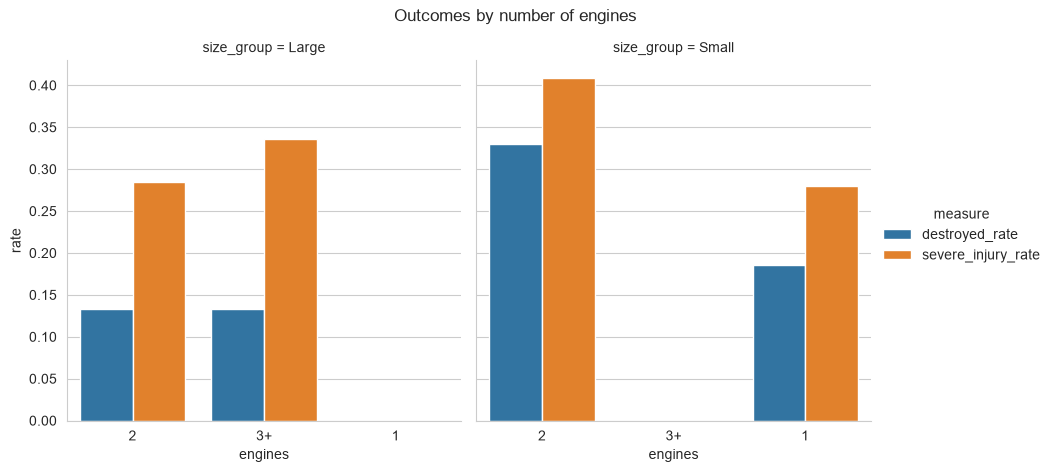

Small engines vs destroyed: chi-square p-value = 8.618220655793245e-147
Large engines vs destroyed: chi-square p-value = 0.9264319086098293


In [16]:
eng_df = df.dropna(subset=['number_of_engines'])
eng_df = eng_df[eng_df['number_of_engines'] > 0].copy()
# group 3 or more engines together (very few of them)
eng_df['engines'] = eng_df['number_of_engines'].clip(upper=3).astype(int).astype(str).replace({'3': '3+'})

engine_tbl = outcome_table(eng_df, 'engines')
display(engine_tbl.round(3))

# only plot groups with 30+ accidents so tiny groups don't mislead
plot_data = engine_tbl[engine_tbl['accidents'] >= 30].melt(id_vars=['size_group', 'engines'],
            value_vars=['destroyed_rate', 'severe_injury_rate'], var_name='measure', value_name='rate')
g = sns.catplot(data=plot_data, kind='bar', x='engines', y='rate', hue='measure', col='size_group', height=4.5)
g.fig.suptitle('Outcomes by number of engines', y=1.04)
g.savefig('images/engines.png', bbox_inches='tight')
plt.show()

for group in ['Small', 'Large']:
    sub = eng_df[eng_df['size_group'] == group]
    chi2, p, dof, exp = stats.chi2_contingency(pd.crosstab(sub['engines'], sub['destroyed']))
    print(group, 'engines vs destroyed: chi-square p-value =', p)

**Factor 2 - Number of engines: discussion**

- **Small planes:** surprisingly, twin-engine planes did *worse* than single-engine planes: 33.0% destroyed vs 18.6%, and 40.9% with a fatal/serious injury vs 28.0%. The chi-square p-value is about 1e-146, so the difference is real. (The 3+ engine group has only 19 accidents, so I don't draw conclusions from it.)
- **Large planes:** two-engine and 3+ engine jets have the same destroyed rate (13.3%) and the difference is not significant (p = 0.93). The single-engine group has 1 accident, so it was left out of the chart.
- A likely reason for the small-plane result is that small twins are heavier, faster and more complex and are often used for longer trips and in tougher conditions, so engine count is probably not the only cause. Extra engines do not seem to make an accident less severe in this data.

### Factor 3: Phase of flight

,broad_phase_of_flight,accidents,destroyed_rate,severe_injury_rate,mean_fatal_serious_share
6,MANEUVERING,4221,0.468,0.552,0.526
1,CLIMB,1229,0.445,0.490,0.445
2,CRUISE,6476,0.345,0.386,0.356
3,DESCENT,1127,0.335,0.383,0.351
0,APPROACH,4107,0.300,0.396,0.354
4,GO-AROUND,1090,0.284,0.337,0.298
8,TAKEOFF,8049,0.217,0.262,0.228
7,STANDING,416,0.130,0.173,0.092
5,LANDING,10889,0.043,0.047,0.036
9,TAXI,1250,0.022,0.034,0.017


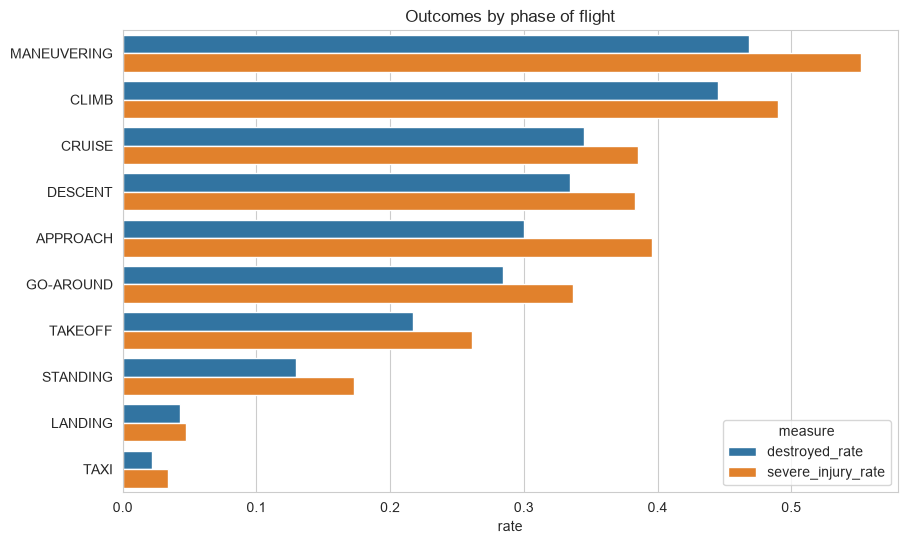

In [17]:
phase_df = df.dropna(subset=['broad_phase_of_flight'])
phase_tbl = phase_df.groupby('broad_phase_of_flight').agg(
    accidents=('destroyed', 'size'),
    destroyed_rate=('destroyed', 'mean'),
    severe_injury_rate=('severe_injury', 'mean'),
    mean_fatal_serious_share=('fatal_serious_share', 'mean')).reset_index()
phase_tbl = phase_tbl[phase_tbl['accidents'] >= 30].sort_values('destroyed_rate', ascending=False)
display(phase_tbl.round(3))

plot_data = phase_tbl.melt(id_vars='broad_phase_of_flight', value_vars=['destroyed_rate', 'severe_injury_rate'],
                           var_name='measure', value_name='rate')
plt.figure(figsize=(10, 6))
sns.barplot(data=plot_data, y='broad_phase_of_flight', x='rate', hue='measure', order=phase_tbl['broad_phase_of_flight'])
plt.title('Outcomes by phase of flight'); plt.ylabel('')
plt.savefig('images/phase_of_flight.png', bbox_inches='tight')
plt.show()

**Factor 3 - Phase of flight: discussion**

- The most dangerous phases are **maneuvering** (46.8% destroyed, 55.2% fatal/serious injury) and **climb** (44.5% / 49.0%), followed by cruise and descent.
- **Landing** has the most accidents (10,889) but they are rarely severe: only 4.3% destroyed and 4.7% with a serious injury. **Taxi** is even lower (2.2% / 3.4%). **Takeoff** is the next most common (8,049) with 21.7% destroyed.
- So "most accidents" is not the same as "worst outcomes". For the insurer, landing accidents are frequent but cheap, while maneuvering and climb accidents are less frequent but are usually total losses with serious injuries.

## Overall conclusion

**Small airplanes:** **Maule** (make), and **Piper PA-20, Maule MX-7, Maule M4** (types) combine low destroyed rates and low injury fractions with significant tests (p < 0.05). **Cessna 180 and 185** are the most reliable choices because of their large sample sizes.

**Large airplanes:** by make, **Bombardier, Embraer and McDonnell Douglas** are the best; by type, **Boeing 757, Bombardier CL-600 and Boeing 727** (tentative, p about 0.15 because there is little data). I can't prove any single large type is safer than the others.

**Factors:** bad weather (IMC) multiplies the chance that a small plane is destroyed by about 3.6 times (60.4% vs 16.7%); small twin-engine planes had worse outcomes than single-engine ones; and maneuvering/climb are the most dangerous phases while landing/taxi accidents are usually minor.

**Limitations**
- The data only contains accidents and no flight hours, so I can't compare how *often* each plane crashes.
- Large planes have few accidents, so many comparisons for them are not statistically significant.
- I filled missing aircraft categories using other records of the same make/model, and missing injury counts with 0, which may add some bias.
- Make/model names are only partly standardised, and plane "families" combine different versions.
- The small/large rule is an assumption based on the 20-passenger threshold.